# Which stars belong together? — Instructor solutions
*Galactic archaeology with Gaia and Rubin*  
**Ani Chiti · Ioana Ciucă · Stanford PHYSICS 367**

On Monday, Ani picked out stars in Reticulum II by their colour and brightness, then checked where they fell on the sky. Today we’ll start with motion. If we pick stars that move together, do they also cluster on the sky or line up in a colour–magnitude diagram?

Start with two clusters, the Pleiades and M5. Then take two stars that might belong to the SGP-S stream and look for them in Rubin images using the catalogue of objects measured in those images.

Please remember what we learn in this session will be useful for the upcoming [Gaia DR4 Sprint at KIPAC, December 2–4](https://kipac.stanford.edu/events/kipac-workshops/kipac-gaia-dr4-x-agentic-ai-sprint-decoding-milky-way-stanford)

Run the cells in order with the LSST kernel. Exercise 3 fills in the Rubin IDs, separations, magnitudes and figures from the archive response.

## Before you start · 5 min

Two stars look close together on the sky. What would you measure to find out whether they might belong to the same cluster? Discuss with your neighbour.

| Gaia column | What it measures |
|---|---|
| `ra`, `dec` | Right ascension and declination in degrees. |
| `phot_g_mean_mag` | Apparent brightness in Gaia’s G band. Smaller magnitudes are brighter. |
| `bp_rp` | Colour (BP − RP). Larger values are redder. |
| `pmra`, `pmdec` | Proper motion in right ascension and declination, in milliarcseconds per year (mas/yr). Gaia includes the cos(dec) factor in `pmra`. |
| `parallax` | The apparent shift in position as Earth orbits the Sun, in milliarcseconds (mas). Nearer stars have larger parallaxes. |

On the Rubin Science Platform, open this notebook with the **LSST** kernel and run the two setup cells. The Gaia downloads come from ESA. Exercise 3 uses the Rubin catalogue through your RSP session.

**One possible answer.** I’d compare the parallaxes and their errors first. Two stars can look close together while lying at different distances. If the distances agree, I’d ask whether their proper motions also agree and where the stars fall on the cluster’s CMD.

In [8]:
from pathlib import Path
from astroquery.gaia import Gaia
import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table
from IPython.display import display

plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 11, 'axes.spines.top': False,
    'axes.spines.right': False, 'axes.grid': False,
    'figure.constrained_layout.use': True,
})
TEAL, ORANGE, GREY = '#007C83', '#C76D33', '#B7BEC5'

data_dir = Path('gaia_data')
data_dir.mkdir(exist_ok=True)

def save_sample(table, query, name):
    path = data_dir / f'{name}.ecsv'
    table.write(path, format='ascii.ecsv', overwrite=True)
    path.with_suffix('.adql').write_text(query, encoding='utf-8')
    print(f'{len(table):,} sources saved to {path}')

In [6]:
from io import BytesIO
import requests

def download_csv(query):
    """Request fresh rows from the public ESA TAP service."""
    endpoint = 'https://gea.esac.esa.int/tap-server/tap/sync'
    parameters = dict(REQUEST='doQuery', LANG='ADQL', FORMAT='csv',
                      MAXREC=100000, QUERY=query)
    response = requests.get(endpoint, params=parameters, timeout=(10, 90))
    response.raise_for_status()
    return Table.read(BytesIO(response.content), format='ascii.csv')

def download_cluster(query):
    """Retrieve a Gaia table and check its size against an archive count."""
    where = query.split('FROM', 1)[1]
    expected = int(download_csv('SELECT COUNT(*) AS n FROM' + where)[0][0])
    try:
        job = Gaia.launch_job_async(query)
        result = job.get_results()
        if len(result) == expected:
            return result
        print(f'Received {len(result):,} of {expected:,} rows. Requesting CSV from ESA.')
    except Exception as error:
        print(f'The asynchronous job failed ({type(error).__name__}). Trying ESA’s CSV endpoint.')
    result = download_csv(query)
    if len(result) != expected:
        raise RuntimeError(f'Incomplete download: {len(result):,} of {expected:,} rows. Rerun this cell.')
    return result

## 1. The Pleiades · 10 min

This query takes stars within 1° of Alcyone, in the Pleiades. We want stars brighter than G = 20 with a measured colour and proper motion, a good astrometric fit, and a parallax uncertainty below 10%.

Find the sky radius and the parallax cut in the query. Then run it and look at the first five stars. [ESA’s Pleiades tutorial](https://github.com/esa/gaia-jupyter-notebooks/blob/main/data-release-3-tutorials/tutorial_use_case_pleiades.ipynb)

In [9]:
query = """
SELECT source_id, ra, dec, pmra, pmdec, phot_g_mean_mag, bp_rp
FROM gaiadr3.gaia_source
WHERE 1=CONTAINS(POINT('ICRS', ra, dec), CIRCLE('ICRS', 56.87125, 24.10493, 1.0))
  AND ruwe < 1.4
  AND parallax_over_error > 10
  AND phot_g_mean_mag < 20.0
  AND bp_rp IS NOT NULL
  AND pmra IS NOT NULL
  AND pmdec IS NOT NULL
"""
pleiades = download_cluster(query)
save_sample(pleiades, query, "pleiades_dr3")
display(pleiades[:5])

500 Error 500:
null
The asynchronous job failed (HTTPError). Trying ESA’s CSV endpoint.
4,001 sources saved to gaia_data/pleiades_dr3.ecsv


source_id,ra,dec,pmra,pmdec,phot_g_mean_mag,bp_rp
int64,float64,float64,float64,float64,float64,float64
64914689765066880,56.942132809715304,23.264002336633954,2.3710636895317894,-2.8567051493746107,15.678613,1.0443707
64921699151684736,57.20314528180409,23.214140123383775,1.8828411216458092,-4.5661621329302235,15.64582,1.0055113
64922283267331968,57.3013765497648,23.228140474524007,19.729432027709375,-46.0451440559743,13.63343,1.8176136
64931354238233344,57.53671472119043,23.408378902202454,3.4510352115625387,-1.1477909020753505,16.56789,1.3283129
64933862499074816,57.07490054871949,23.207116636374398,-5.986962120890803,-18.695098431823972,17.942547,2.117113


### Select stars by proper motion

The circle on the left is centred on the Pleiades’ motion, (20, −45) mas/yr. The colour–magnitude diagram (CMD) on the right shows the stars inside that circle in teal. Brighter stars are at the top.

Run the cell with `radius_pm = 3.0`, then try 6.0 mas/yr. Where do the extra stars fall in the CMD?

431 Pleiades candidates


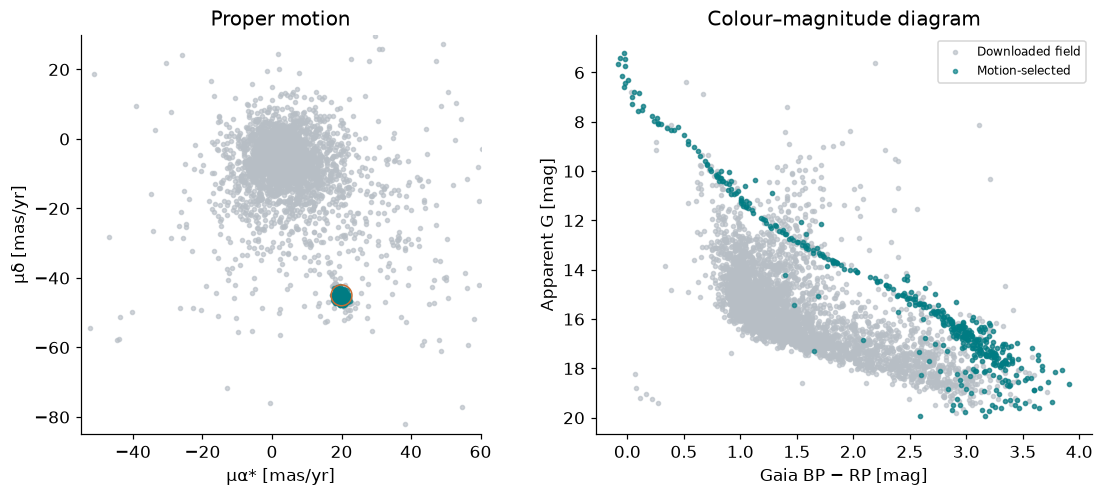

In [10]:
radius_pm = 3.0  # mas/yr
offset = np.hypot(pleiades['pmra'] - 20, pleiades['pmdec'] + 45)
selected = pleiades[offset < radius_pm]
print(f'{len(selected):,} Pleiades candidates')

fig, (ax_pm, ax_cmd) = plt.subplots(1, 2, figsize=(10, 4.4))
for table, colour, label in [(pleiades, GREY, 'Downloaded field'),
                             (selected, TEAL, 'Motion-selected')]:
    ax_pm.scatter(table['pmra'], table['pmdec'], s=7, color=colour, alpha=.65)
    ax_cmd.scatter(table['bp_rp'], table['phot_g_mean_mag'], s=7,
                   color=colour, alpha=.65, label=label)
ax_pm.add_patch(plt.Circle((20, -45), radius_pm, fill=False, color=ORANGE))
ax_pm.set(xlim=(-55, 60), ylim=(-85, 30), aspect='equal',
          xlabel='μα* [mas/yr]', ylabel='μδ [mas/yr]', title='Proper motion')
ax_cmd.invert_yaxis()
ax_cmd.set(xlabel='Gaia BP − RP [mag]', ylabel='Apparent G [mag]', title='Colour–magnitude diagram')
ax_cmd.legend(fontsize=8)
plt.show()

**The query.** The last argument of `CIRCLE` sets the 1° radius. The cut `parallax_over_error > 10` keeps positive parallaxes whose fractional uncertainties are below 10%.

**The wider circle.** The saved class sample has 4,001 stars. Widening the radius from 3 to 6 mas/yr takes the selection from 431 to 456. Some newcomers extend the red, faint end of the sequence. One lies well to the blue, near BP − RP = 0.9 and G = 17.4. The extra 25 are a mixture worth checking.

In [ ]:
inside_3 = offset < 3.0
inside_6 = offset < 6.0
print(f'3 mas/yr: {inside_3.sum()} candidates')
print(f'6 mas/yr: {inside_6.sum()} candidates ({(inside_6 & ~inside_3).sum()} added)')

## 2. Find M5 · 15 min

M5 is much farther away than the Pleiades. What would happen to its stars if you kept the same parallax cut?

Compare this query with the first one, then run it. It takes a random subset of stars within 0.6° of M5, down to G = 20. The BP and RP cuts select stars with well-measured colours.

In [11]:
query = """
SELECT source_id, ra, dec, pmra, pmdec, phot_g_mean_mag, bp_rp
FROM gaiadr3.gaia_source
WHERE 1=CONTAINS(POINT('ICRS', ra, dec), CIRCLE('ICRS', 229.6384, 2.081, 0.6))
  AND ruwe < 1.4
  AND phot_bp_mean_flux_over_error > 10
  AND phot_rp_mean_flux_over_error > 10
  AND random_index < 300000000
  AND phot_g_mean_mag < 20.0
  AND bp_rp IS NOT NULL
  AND pmra IS NOT NULL
  AND pmdec IS NOT NULL
"""
stars = download_cluster(query)
save_sample(stars, query, "m5_dr3")
display(stars[:5])

INFO: Query finished. [astroquery.utils.tap.core]
2,798 sources saved to gaia_data/m5_dr3.ecsv


source_id,ra,dec,pmra,pmdec,phot_g_mean_mag,bp_rp
,deg,deg,mas / yr,mas / yr,mag,mag
int64,float64,float64,float64,float64,float32,float32
4420697859385881216,229.86395624861254,1.5642270829967708,-0.7103223261732448,-0.8916827041599908,18.183031,0.35428047
4420705074930999680,229.89475846445495,1.7596943752097913,-1.4083561908881346,0.5899644004106932,18.518286,0.9448948
4420797541282524416,230.1816811358666,1.8497776619983315,-0.7900390976814392,-4.9505729124132065,17.158625,0.99489784
4420810112651208064,230.22557419590245,2.024718533731777,3.805204112317377,-23.877100414736756,18.695774,2.7719402
4421421681635379328,229.47442126973777,1.5182564023901046,-2.8051415379351967,1.0499555510801286,19.600574,1.537983


### Estimate M5’s proper motion

Each hexagon counts stars with similar proper motions. Find the clump and read its centre off the axes. Write down both numbers, including their signs.

My estimate of (μα*, μδ) is (___, ___) mas/yr.

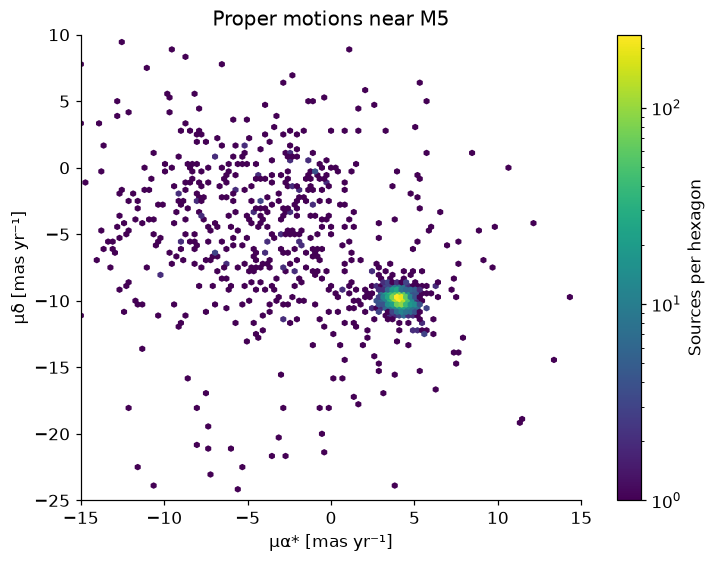

In [12]:
fig, ax = plt.subplots(figsize=(6.4, 5))
h = ax.hexbin(stars['pmra'], stars['pmdec'], gridsize=110, mincnt=1,
              bins='log', extent=(-15, 15, -25, 10), cmap='viridis')
fig.colorbar(h, ax=ax, label='Sources per hexagon')
ax.set(xlim=(-15, 15), ylim=(-25, 10), xlabel='μα* [mas yr⁻¹]',
       ylabel='μδ [mas yr⁻¹]', title='Proper motions near M5')
plt.show()

Enter your estimate below. A star lies 0.6 mas/yr from your centre along one axis and 0.8 mas/yr along the other. Would you include it with a radius of 0.75 mas/yr? What about 2.0 mas/yr?

Try both radii. Look at the teal stars in the sky map and the CMD. What evidence do you see that they belong to M5?

1,710 / 2,798 stars selected as M5 candidates


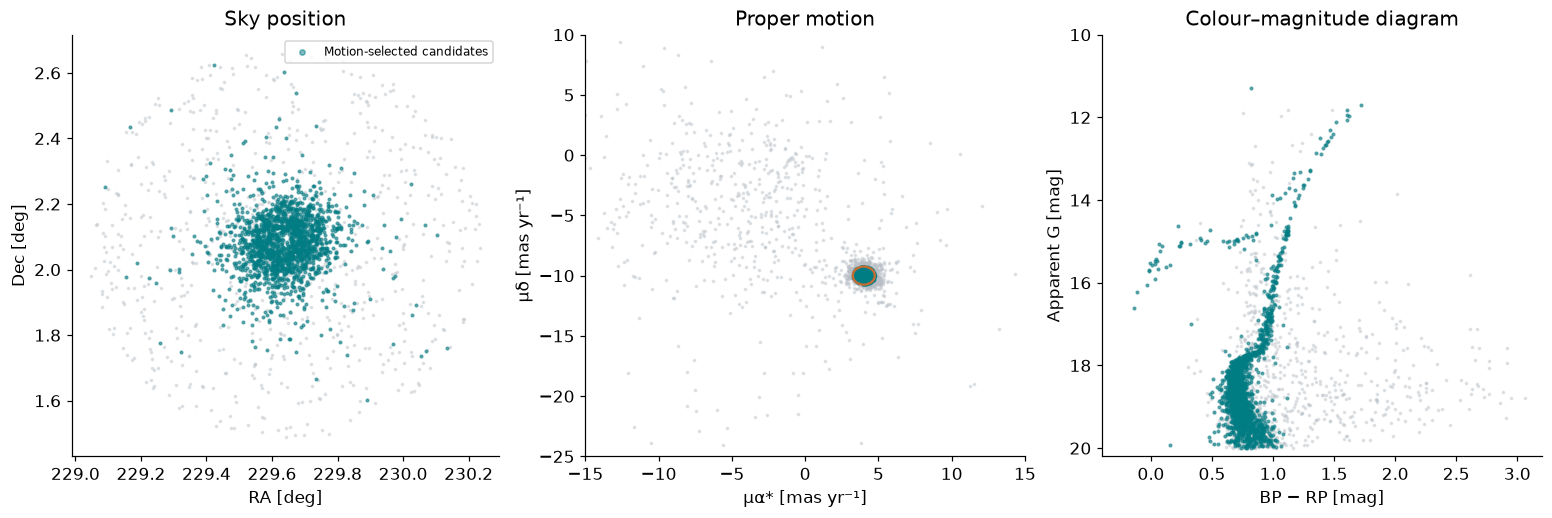

In [13]:
pmra_c, pmdec_c = 4.0, -10.0  # Replace with your reading of the clump centre.
radius_pm = 0.75              # Widen to 2.0 mas/yr, then compare the outer panels.
delta_pm = np.hypot(stars['pmra'] - pmra_c, stars['pmdec'] - pmdec_c)
member = delta_pm < radius_pm
candidates = stars[member]
print(f'{len(candidates):,} / {len(stars):,} stars selected as M5 candidates')

fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
views = [('ra', 'dec', 'RA [deg]', 'Dec [deg]', 'Sky position'),
         ('pmra', 'pmdec', 'μα* [mas yr⁻¹]', 'μδ [mas yr⁻¹]', 'Proper motion'),
         ('bp_rp', 'phot_g_mean_mag', 'BP − RP [mag]', 'Apparent G [mag]',
          'Colour–magnitude diagram')]
for ax, (x, y, xlabel, ylabel, title) in zip(axes, views):
    ax.scatter(stars[x], stars[y], s=2, color=GREY, alpha=.35, rasterized=True)
    ax.scatter(candidates[x], candidates[y], s=3, color=TEAL, alpha=.5,
               label='Motion-selected candidates', rasterized=True)
    ax.set(xlabel=xlabel, ylabel=ylabel, title=title)
axes[0].set_aspect(1 / np.cos(np.deg2rad(2.081)))
axes[0].legend(loc="upper right", fontsize=8, markerscale=2)
axes[1].add_patch(plt.Circle((pmra_c, pmdec_c), radius_pm,
                             fill=False, color=ORANGE, lw=1.5))
axes[1].set(xlim=(-15, 15), ylim=(-25, 10))
axes[2].set(xlim=(-.4, 3.2), ylim=(20.2, 10))
fig.savefig('m5_membership.png', dpi=180, bbox_inches='tight')
plt.show()

Which radius would you keep? Point to one feature in the sky map or the CMD that helped you decide.

**M5.** At this distance many real members have small parallaxes with large fractional uncertainties. Keeping the Pleiades parallax cut would throw away much of the cluster. I read the centre of the motion clump as roughly (+4, −10) mas/yr. An offset of (0.6, 0.8) has length 1.0 mas/yr, so only the 2.0 mas/yr circle includes that star.

With this centre the two cuts keep 1,710 and 2,120 of the 2,798 stars. I’d use 2.0 mas/yr to study the fainter members. The 410 extra stars are mostly faint (median G ≈ 19.34) and still concentrate around M5. For a cleaner list of bright candidates I’d use 0.75 mas/yr. The concentration on the sky and the red-giant sequence in the CMD give independent checks on a cut made using motion alone.

In [ ]:
for cut in (0.75, 2.0):
    print(f'{cut:.2f} mas/yr: {np.count_nonzero(delta_pm < cut)} candidates')
added = stars[(delta_pm >= 0.75) & (delta_pm < 2.0)]
if len(added):
    print(f"Median G of the extra stars: {np.median(added['phot_g_mean_mag']):.2f}")

## 3. Find two stream stars in Rubin · 25 min

SGP-S is a thin stream of stars about 9.5 kpc from the Sun. Yang and colleagues traced it over 58° using Gaia colours and proper motions. A short stretch crosses ELAIS-S1, a field Rubin imaged repeatedly. We’ll work in a circle just 0.3° across. [SGP-S discovery paper](https://arxiv.org/abs/2208.05176) · [Rubin’s ELAIS-S1 depth map, Figure 6](https://dp2.lsst.io/tutorials/notebook/301/notebook-301-3.html#depth-and-deep-coadd-plots)

Two stars in this field are published SGP-S candidates. Their Gaia IDs are given below. Start by finding them on a proper-motion plot of all the Gaia stars in the field. How closely do the two motions agree compared with the rest of the field? [Published candidate list](https://github.com/abonaca/streams_overview/blob/2663cc06e5ced4b02850de15140bc9f136f3341b/data/members/streams/SGP-S.fits)

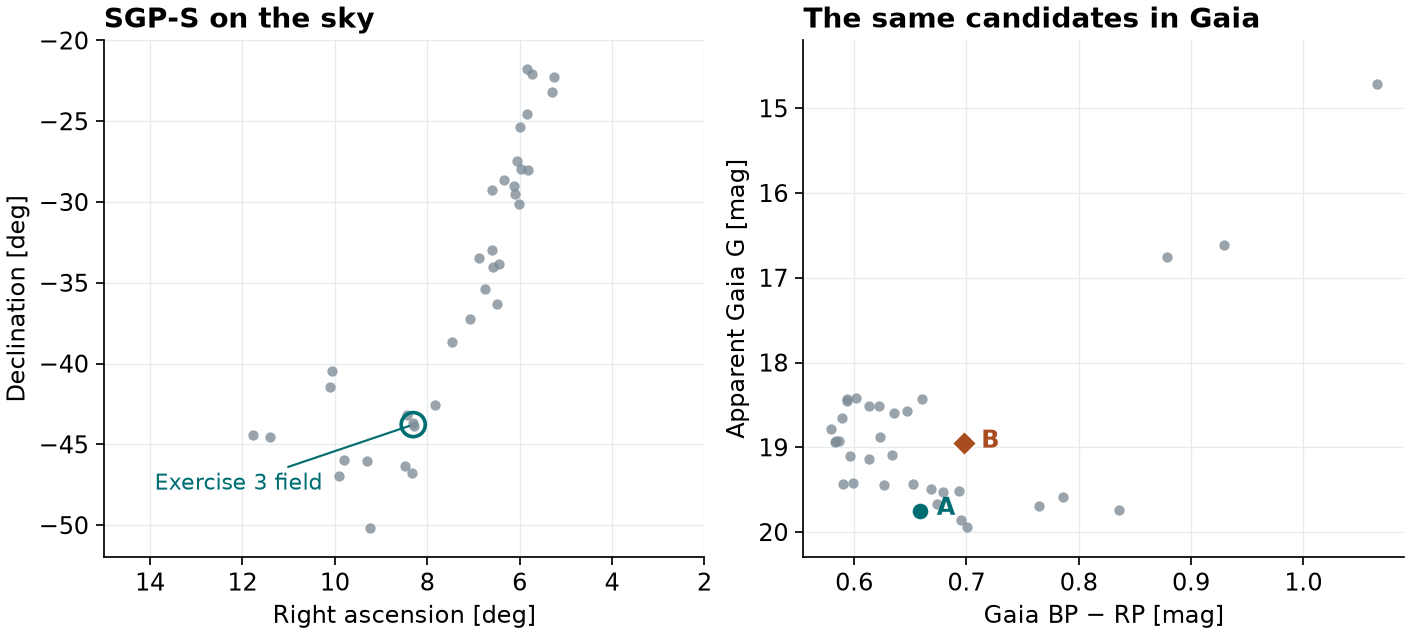

Each grey point is a published SGP-S candidate. The circle marks our field, enlarged so you can see it. **A** and **B** follow the order of the two Gaia IDs below. Which star looks brighter? Which is bluer?

In [ ]:
from astropy.coordinates import SkyCoord
import astropy.units as u
from lsst.rsp import get_tap_service

field_ra, field_dec = 8.303, -43.776  # degrees
target_ids = [4980391162444934656, 4980409235667391360]  # Gaia DR3 integer IDs

gaia_query = f"""
SELECT source_id, ra, dec, pmra, pmdec, pmra_error, pmdec_error, phot_g_mean_mag
FROM gaiadr3.gaia_source
WHERE 1 = CONTAINS(POINT('ICRS', ra, dec),
                   CIRCLE('ICRS', {field_ra}, {field_dec}, 0.15))
  AND pmra IS NOT NULL AND pmdec IS NOT NULL
"""
gaia_field = download_csv(gaia_query)
save_sample(gaia_field, gaia_query, 'sgps_gaia_dr3')
if not set(target_ids).issubset(gaia_field['source_id']):
    raise ValueError('The Gaia download is missing a target. Rerun this cell before matching.')

Write your selection and plot below. Use the full integer IDs to select the two rows. The columns `pmra_error` and `pmdec_error` give the uncertainties in mas/yr.

In [ ]:
targets = Table(rows=[gaia_field[gaia_field['source_id'] == sid][0] for sid in target_ids],
                names=gaia_field.colnames)
display(targets['source_id', 'pmra', 'pmra_error', 'pmdec', 'pmdec_error'])

fig, ax = plt.subplots(figsize=(6.4, 4.8))
ax.scatter(gaia_field['pmra'], gaia_field['pmdec'], s=6, color=GREY, alpha=.6)
for star, label, colour, marker in zip(targets, 'AB', [TEAL, ORANGE], ['o', 'D']):
    ax.errorbar(star['pmra'], star['pmdec'], xerr=star['pmra_error'],
                yerr=star['pmdec_error'], color=colour, fmt=marker, capsize=3,
                label=f'Star {label}', zorder=3)
ax.set(xlim=(-10, 12), ylim=(-10, 12), aspect='equal', xlabel='μα* [mas/yr]',
       ylabel='μδ [mas/yr]', title='Proper motions near SGP-S')
ax.legend()
plt.show()

**Reading the Gaia plots.** B is brighter (G ≈ 18.95 versus 19.75). A is slightly bluer (BP − RP ≈ 0.66 versus 0.70). I find motions of (+2.31, +2.56) for A and (+1.94, +3.08) mas/yr for B. They lie about 0.63 mas/yr apart in the motion plane. Their uncertainties are a few tenths of a mas/yr per component. Other field stars can also have similar motions.

### Which Rubin object goes with each Gaia star?

Run the cell below. It reads the DP2 Object catalogue made from stacked Rubin images. The Rubin search extends a little past the Gaia field so you can still find neighbours near the edge. We keep objects brighter than *r* = 22.

In [ ]:
rubin_query = f"""
SELECT objectId, coord_ra, coord_dec, g_psfMag, r_psfMag
FROM dp2.Object
WHERE CONTAINS(POINT('ICRS', coord_ra, coord_dec),
               CIRCLE('ICRS', {field_ra}, {field_dec}, 0.16)) = 1
  AND r_psfMag < 22
"""
rubin_field = get_tap_service('tap').search(rubin_query, maxrec=100000).to_table()
if not len(rubin_field):
    raise ValueError('The Rubin query returned no objects. Check the field centre and the DP2 table.')
if len(rubin_field) == 100000:
    raise ValueError('The Rubin query reached the row limit. Check completeness before matching.')
print(f'{len(rubin_field):,} Rubin objects')
display(rubin_field[:3])

Write the match yourself. For each Gaia candidate, measure the angular separation to the Rubin objects. Both catalogues give RA and Dec in degrees. `SkyCoord.separation` measures angles on the sky.

Make a two-row table. For each Gaia ID, report how many Rubin objects lie within **1 arcsec**. If exactly one does, give its `objectId`, separation in arcsec and *r* magnitude. Label an empty circle “no match” and a circle with several objects “ambiguous”.

Pick one row to explain to your neighbour. What observation supports the identification across catalogues? What measurement would help you decide whether this star belongs to SGP-S?

For the figure below, put each unique pair in `rubin_ids` using the integer Gaia ID as the key and the integer Rubin ID as the value. Leave out any target whose identification is uncertain.

In [ ]:
rubin_sky = SkyCoord(rubin_field['coord_ra'], rubin_field['coord_dec'], unit='deg')
rubin_ids = {}
match_rows = []
for star, label in zip(targets, 'AB'):
    sid = int(star['source_id'])
    position = SkyCoord(star['ra'], star['dec'], unit='deg')
    separation = position.separation(rubin_sky).arcsec
    neighbours = np.flatnonzero(separation <= 1.0)
    if len(neighbours) == 1:
        idx = neighbours[0]
        rubin_ids[sid] = int(rubin_field['objectId'][idx])
        match_rows.append((label, sid, 1, 'unique', str(rubin_ids[sid]),
                           separation[idx], float(rubin_field['r_psfMag'][idx])))
    else:
        status = 'no match' if len(neighbours) == 0 else 'ambiguous'
        match_rows.append((label, sid, len(neighbours), status, '—', np.nan, np.nan))

matches = Table(rows=match_rows, names=['Star', 'Gaia source_id', 'Neighbours', 'Status',
                                        'Rubin objectId', 'Separation [arcsec]', 'r [mag]'])
matches['Separation [arcsec]'].format = '.3f'
matches['r [mag]'].format = '.2f'
display(matches)

### Put your matches on the sky and the CMD

Run the next cell after you fill in `rubin_ids`. On the sky map, an outline marks each Gaia target and a plus marks its Rubin counterpart. On the CMD, compare your matches to the other Rubin objects with measured *g* and *r*. Which target is brighter in *r*? Does the colour ordering agree with the Gaia diagram above?

In [ ]:
g_mag = np.ma.asarray(rubin_field['g_psfMag'], dtype=float).filled(np.nan)
r_mag = np.ma.asarray(rubin_field['r_psfMag'], dtype=float).filled(np.nan)
has_colour = np.isfinite(g_mag) & np.isfinite(r_mag)
fig, (sky, cmd) = plt.subplots(1, 2, figsize=(10, 4.6))
sky.scatter(rubin_field['coord_ra'], rubin_field['coord_dec'], s=4, color=GREY, alpha=.45)
cmd.scatter((g_mag - r_mag)[has_colour], r_mag[has_colour], s=4, color=GREY, alpha=.45)

for gaia_id, label, colour, marker in zip(target_ids, 'AB', [TEAL, ORANGE], ['o', 'D']):
    star = gaia_field[gaia_field['source_id'] == gaia_id][0]
    sky.scatter(star['ra'], star['dec'], marker=marker, s=110, facecolors='none',
                edgecolors=colour, linewidths=1.7)
    sky.annotate(label, (star['ra'], star['dec']), xytext=(9, 3),
                 textcoords='offset points', color=colour, weight='bold')
    if gaia_id not in rubin_ids:
        continue
    idx, = np.flatnonzero(rubin_field['objectId'] == rubin_ids[gaia_id])
    sky.scatter(rubin_field['coord_ra'][idx], rubin_field['coord_dec'][idx],
                marker='+', s=55, color=colour)
    if has_colour[idx]:
        x, y = g_mag[idx] - r_mag[idx], r_mag[idx]
        cmd.scatter(x, y, marker=marker, s=60, color=colour)
        cmd.annotate(label, (x, y), xytext=(8, 3), textcoords='offset points',
                     color=colour, weight='bold')
    else:
        print(f'{label} has a Rubin counterpart but lacks a usable g − r colour.')

sky.set(xlabel='RA [deg]', ylabel='Dec [deg]', title='Gaia targets in the Rubin field')
sky.set_aspect(1 / np.cos(np.deg2rad(field_dec)))
sky.invert_xaxis()
cmd.set(xlabel='Rubin g − r [mag]', ylabel='Apparent r [mag]', title='Rubin colour–magnitude diagram')
cmd.invert_yaxis()
plt.show()

In [ ]:
if all(sid in rubin_ids for sid in target_ids):
    ia, ib = [np.flatnonzero(rubin_field['objectId'] == rubin_ids[sid])[0] for sid in target_ids]
    for label, idx in zip('AB', (ia, ib)):
        print(f'{label}: r = {r_mag[idx]:.3f}, g − r = {g_mag[idx] - r_mag[idx]:.3f}')
    if r_mag[ia] != r_mag[ib]:
        print(f"{'A' if r_mag[ia] < r_mag[ib] else 'B'} is brighter in Rubin r.")
    if has_colour[ia] and has_colour[ib]:
        delta = (g_mag[ia] - r_mag[ia]) - (g_mag[ib] - r_mag[ib])
        print('Colour ordering compared to Gaia:', 'same' if delta < 0 else
              ('reversed' if delta > 0 else 'tied'))
else:
    print('The match table does not identify a unique Rubin counterpart for both targets.')

**What the identification means.** For a unique match I’d cite its separation and the absence of a second Rubin object inside the search circle. On this field-scale map the Gaia and Rubin markers can overlap completely, so I’d quote the separation from the table. Two position measurements can identify the same star even if it is an unrelated field star. A radial velocity consistent with other SGP-S candidates would give us a separate test of membership. Gaia BP − RP and Rubin *g − r* also use different filters, so I’d compare the ordering of the two stars across diagrams.

## Optional stretch · How often would you match by chance? · 8 min

Two targets make a small sample. Use **all** the stars in `gaia_field` to test your matching rule. Count how many have exactly one Rubin neighbour within 1 arcsec.

Now move every Gaia position 10 arcsec north and repeat, keeping the Rubin positions fixed. Use the same stars and search radius both times. What fraction of the shifted positions still have a match? What does that tell you about the two identifications above?

If you need a hint, `astropy.coordinates.search_around_sky` returns all pairs inside an angular radius.

In [ ]:
from astropy.coordinates import search_around_sky

gaia_sky = SkyCoord(gaia_field['ra'], gaia_field['dec'], unit='deg')
shifted_sky = gaia_sky.directional_offset_by(0 * u.deg, 10 * u.arcsec)
for label, positions in [('Original', gaia_sky), ('Shifted north', shifted_sky)]:
    gaia_idx, _, _, _ = search_around_sky(positions, rubin_sky, 1 * u.arcsec)
    neighbour_count = np.bincount(gaia_idx, minlength=len(positions))
    n_unique = np.count_nonzero(neighbour_count == 1)
    print(f'{label}: {n_unique:,} / {len(positions):,} positions have one neighbour '
          f'({n_unique / len(positions):.2%}).')

**Reading the control.** The shifted fraction estimates how often a position in this field lands close to exactly one catalogue object by chance. A much higher fraction at the original positions supports the positional identifications. The control describes the field as a whole. Crowding and brightness can make an individual case easier or harder.

## Gaia references

- [Select cluster stars by proper motion](https://github.com/esa/gaia-jupyter-notebooks/blob/main/data-release-3-tutorials/tutorial_use_case_pleiades.ipynb)
- [Check column units and convert them](https://github.com/esa/gaia-jupyter-notebooks/blob/main/data-release-3-tutorials/tutorial_change_units.ipynb)
- [Retrieve spectra and epoch data with DataLink](https://github.com/esa/gaia-jupyter-notebooks/blob/main/data-release-3-tutorials/tutorial_datalink_download.ipynb)
- [ESA notebooks by data release](https://github.com/esa/gaia-jupyter-notebooks)
- [Astroquery Gaia documentation](https://astroquery.readthedocs.io/en/stable/gaia/gaia.html)

For DR4, check the column names, units, reference epoch, and recommended quality cuts. Source identifiers can change between releases. Save the query and release with your results.

### Credits

The cluster exercises adapt ESA’s Pleiades tutorial (v1.2, May 2025). The SGP-S exercise uses Gaia DR3 astrometry and Rubin DP2 Object photometry. The candidate list accompanies Bonaca & Price-Whelan’s [Stellar streams in the Gaia era](https://doi.org/10.1016/j.newar.2024.101713). [Rubin DP2 Object catalogue](https://dp2.lsst.io/products/catalogs/object.html)

ESA and the Gaia Data Processing and Analysis Consortium (DPAC) provided the Gaia data. GPT 6.2 Astra Ultra helped with the notebook. [Gaia data credits](https://www.cosmos.esa.int/web/gaia-users/credits)

<details><summary>ESA licence and CHANGELOG</summary>

Copyright (c) European Space Agency, 2025. The ESA Pleiades use case is subject to the ESA-PL Permissive (Type 3), v2.4. Adaptation for Ioana Ciucă, Stanford PHYSICS 367, November 17, 2026. This classroom version adds a CMD, M5 and SGP-S queries, a Gaia–Rubin DP2 cross-match and a shifted-position test. [Course contact](https://web.stanford.edu/group/gfc/Fall26_367/).

European Space Agency Public License (ESA-PL) Permissive (Type 3) – v2.4


1 Definitions
1.1 “Contributor” means (a) the individual or legal entity that originally creates or later modifies the Software and (b) each subsequent individual or legal entity that creates or contributes to the creation of Modifications.
1.2 “Contributor Version” means the version of the Software on which the Contributor based its Modifications.
1.3 “Distribution” and “Distribute” means any act of selling, giving, lending, renting, distributing, communicating, transmitting, or otherwise making available, physically or electronically or by any other means, copies of the Software or Modifications.
1.4 “ESA” means the European Space Agency.
1.5 “License” means this document.
1.6  “Licensor” means the individual or legal entity that Distributes the Software under the License to You.
1.7 “Modification” means any work or software created that is based upon or derived from the Software (or portions thereof) or a modification of the Software (or portions thereof). For the avoidance of doubt, linking a library to the Software results in a Modification.
1.8 “Object Code” means any non-Source Code form of the Software and/or Modifications.
1.9 “Patent Claims” (of a Contributor) means any patent claim(s), owned at the time of the Distribution or subsequently acquired, including without limitation, method, process and apparatus claims, in any patent licensable by a Contributor which would be infringed by making use of the rights granted under Sec. 2.1, including but not limited to make, have made, use, sell, offer for sale or import of the Contributor Version and/or such Contributor’s Modifications (if any), either alone or in combination with the Contributor Version. “Licensable” means having the right to grant, whether at the time of the Distribution or subsequently acquired, the rights conveyed herein.
1.10 “Software” means the software Distributed under this License by the Licensor, in Source Code and/or Object Code form.
1.11 “Source Code” means the preferred, usually human readable form of the Software and/or Modifications in which modifications are made and the associated documentation included in or with such code.
1.12 “You” means an individual or legal entity exercising rights under this License (the licensee).


2 Grant of Rights
2.1 Copyright. The Licensor, and each Contributor in respect of such Contributor’s Modifications, hereby grants You a world-wide, royalty-free, non-exclusive license under Copyright, subject to the terms and conditions of this License, to:
• use the Software;
• reproduce the Software by any or all means and in any or all form;
• Modify the Software and create works based on the Software;
• communicate to the public, including making available, display or perform the Software or copies thereof to the public;
• Distribute, sublicense, lend and rent the Software.
The license grant is perpetual and irrevocable, unless terminated pursuant to Sec. 7.

2.2 Patents. Each Contributor in respect of such Contributor’s Modifications, hereby grants You a world-wide, royalty-free, non-exclusive, sub-licensable license under Patent Claims to the extent necessary to make use of the rights granted under Sec. 2.1, including but not limited to make, have made, use, sell, offer for sale, import, export and Distribute such Contributor’s Modifications and the combination of such Contributor’s Modifications with the Contributor Version (collectively called the “Patent Licensed Version” of the Software).
No patent license is granted for claims that are infringed:
• only as a consequence of further modification of the Patent Licensed Version; or
• by the combination of the Patent Licensed Version with other software or other devices or hardware, unless such combination was an intended use case of the Patent Licensed Version (e.g. a general purpose library is intended to be used with other software, a satellite navigation software is intended to be used with appropriate hardware); or
• by a Modification under Patent Claims in the absence of the Contributor’s Modifications or by a combination of the Contributor’s Modifications with software other than the Patent Licensed Version or Modifications thereof.

2.3 Trademark. This License does not grant permission to use trade names, trademarks, services marks, logos or names of the Licensor, except as required for reasonable and customary use in describing the origin of the Software and as reasonable necessary to comply with the obligations of this License (e.g. by reproducing the content of the notices). For the avoidance of doubt, upon Distribution of Modifications You must not use the Licensor’s or ESA’s trademarks, names or logos in any way that states or implies, or can be interpreted as stating or implying, that the final product is endorsed or created by the Licensor or ESA.


3 Distribution
3.1 No Copyleft.
You may Distribute the Software and/or Modifications, as Source Code or Object Code, under any license terms, provided that
(a) notice is given of the use of the Software and the applicability of this License to the Software; and
(b) You make best efforts to ensure that further Distribution of the Software and/or Modifications (including further Modifications) is subject to the obligations set forth in this Sec. 3.1 (a) and (b).


4 Notices
The following obligations apply in the event of any Distribution of the Software and/or Modifications as Source Code and/or Object Code:
4.1 You must include a copy of this License and all of the notices set out in this Sec. 4.
4.2 You may not remove or alter any copyright, patent, trademark and attribution notices nor any of the notices set out in this Sec. 4, except as necessary for your compliance with this License or otherwise permitted by this License, except for those notices that do not pertain to the Modifications You Distribute.
4.3 Each Contributor must cause its Modification carrying prominent notices stating that the Software has been modified and the date of modification and identify itself as the originator of its Modifications in a manner that reasonably allows identification and contact with the Contributor. The aforementioned notices must at a minimum be in a text file included with the Distribution titled “CHANGELOG”.
4.4 The Software may include a "NOTICE" text file containing general notices. Any Contributor can create such a NOTICE file or add notices to it, alongside or as an addendum to the original text, provided that such notices cannot be construed as modifying the License.
4.5 Each Contributor must identify all of its Patent Claims by providing at a minimum the patent number and identification and contact information in a text file included with the Distribution titled "LEGAL".


5 Warranty and Liability
5.1 Each Contributor warrants and represents that it has sufficient rights to grant the rights to its Modifications conveyed by this License.
5.2 Except as expressly set forth in this License, the Software is provided to You on an “as is” basis and without warranties of any kind, including without limitation merchantability, fitness for a particular purpose, absence of defects or errors, accuracy or non-infringement of intellectual property rights. Mandatory statutory warranty claims, e.g. in the event of wilful deception or fraudulent misrepresentation, shall remain unaffected.
5.3 Except as expressly set forth in this License, neither Licensor nor any Contributor shall be liable, including, without limitation, for direct, indirect, incidental, or consequential damages (including without limitation loss of profit), however caused and on any theory of liability, arising in any way out of the use or Distribution of the Software or the exercise of any rights under this License, even if You have been advised of the possibility of such damages. Mandatory statutory liability claims, e.g. in the event of wilful misconduct, wilful deception or fraudulent misrepresentation, shall remain unaffected.


6 Additional Agreements
While Distributing the Software or Modifications, You may choose to conclude additional agreements, for free or for charge, regarding for example support, warranty, indemnity, liability or liability obligations and/or rights, provided such additional agreements are consistent with this License and do not effectively restrict the recipient’s rights under this License. However, in accepting such obligations, You may act only on Your own behalf and on Your sole responsibility, not on behalf of any other Contributor or Licensor, and only if You agree to indemnify, defend, and hold each Contributor or Licensor harmless for any liability incurred by, or claims asserted against, such Contributor or Licensor by reason of your accepting any such warranty or additional liability.


7 Infringements
7.1 You acknowledge that continuing to use the Software knowing that such use infringes third party rights (e.g. after receiving a third party notification of infringement) would expose you to the risk of
being considered as intentionally infringing third party rights. In such event You should acquire the respective rights or modify the Software so that the Modification is non-infringing.


8 Termination
8.1 This License and the rights granted hereunder will terminate automatically upon any breach by You with the terms of this License if you fail to cure such breach within 30 days of becoming aware of the breach.
8.2 If You institute patent litigation against any entity (including a cross-claim or counterclaim in a lawsuit) alleging that the Software constitutes direct or contributory patent infringement, then any patent and copyright licenses granted to You under this License for the Software shall terminate as of the date such litigation is filed.
8.3 Any licenses validly granted by You under the License prior to termination shall continue and survive termination.


9 Applicable Law, Arbitration and Compliance
9.1 This License is governed by the laws of the ESA Member State where the Licensor resides or has his registered office. “Member States” are the members of the European Space Agency pursuant to Art. 1 of the ESA Convention[Footnote 1]. This licence shall be governed by German law if a dispute arises with the ESA as a Licensor or if the Licensor has no residence or registered office inside a Member State.
9.2 Any dispute arising out of this License shall be finally settled in accordance with the Rules of Arbitration of the International Chamber of Commerce by one or more arbitrators designated in conformity with those rules. Arbitration proceedings shall take place in Cologne, Germany. The award shall be final and binding on the parties, no appeal shall lie against it. The enforcement of the award shall be governed by the rules of procedure in force in the state/country in which it is to be executed.
9.3 For the avoidance of doubt, You are solely responsible for compliance with current applicable requirements of national laws. The Software can be subject to export control laws. If You export the Software it is your responsibility to comply with all export control laws. This may include different requirements, as e.g. registering the Software with the local authorities.
9.4 If it is impossible for You to comply with any of the terms of this License due to statute, judicial order or regulation You must:
(a) comply with the terms of this License to the maximum extent possible; and
(b) describe the limitations and the Object Code and/or Source Code they affect. Such description must be included in the LEGAL notice described in Section 4. Except to the extent prohibited by statute or regulation, such description must be sufficiently detailed for an average recipient to be able to understand it.


10 Miscellaneous
10.1 Only ESA has the right to modify or publish new versions of this License. ESA may assign this right to other individuals or legal entities. Each version will be given a distinguishing version number.
10.2 This License represents the complete agreement concerning subject matter hereof.
10.3 If any provision of this License is held invalid or unenforceable, the remaining provisions of this License shall not be affected. The invalid or unenforceable provision shall be construed and/or reformed to the extent necessary to make it enforceable and valid.


______________________________
[1]: As of January 2020 the Member States are Austria, Belgium, Czech Republic, Denmark, Estonia, Finland, France, Germany, Greece, Hungary, Ireland, Italy, Luxembourg, The Netherlands, Norway, Poland, Portugal, Romania, Spain, Sweden, Switzerland and the United Kingdom.

</details>